# Harmonic events from EEG
**CS1090A · Group 18 · Milestone 2: data wrangling and project redefinition**

**Group members:** Davis Bone, Rose Friedman, Ana Maria Ramirez Diaz, Trent Rogers, Payton Shen

**Repository:** https://github.com/davisbone/Harmonic-EEG

**Question:** Can 21 early EEG voltage features tell standard from deviant middle chords in participants the model was not trained on?

**In short:** Forty musicians listened to three-chord progressions while 64 scalp electrodes recorded EEG. Label-blind source, block-edge, bad-electrode, ICA, and amplitude checks retain 32,935 middle-chord events from 27 participants, each summarized by 21 baseline-corrected regional voltage averages (84.0% standards, 16.0% deviants). This notebook loads the bundled processed table, explains what one row means, accounts for every excluded event, examines the extreme values, and sets up the participant-grouped evaluation for Milestone 3 without fitting a classifier yet. Start Jupyter from the repository root after `uv sync`.

The [visual walkthrough](https://html-preview.github.io/?url=https://github.com/davisbone/Harmonic-EEG/blob/ms2-full-draft/docs/explainer.html) explains the experiment and processing with pictures (it opens in any browser, including on phones). The [methods](docs/methods.md) list every processing choice and its limits.

**Use of generative AI and outside resources.** Earlier prototypes, the processing pipeline (`eeg_pipeline/`), tests, this notebook, the methods document, and the visual walkthrough were developed and reviewed with OpenAI Codex (`GPT-6 Astra`, `GPT-6.1 Sol`, `GPT-6 Luna`), Anthropic Claude Code (`Claude Opus 5.5`), and Google Antigravity (`Gemini 4 Argon`). Complete dataset, study, software, and generative-AI citations appear in [Section 5](#5-references-and-citations) at the end of this notebook.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from eeg_pipeline.config import PREDICTORS, ROIS, WINDOWS

ROOT = Path.cwd()
RESULTS = ROOT / "results"
provenance = json.loads((RESULTS / "provenance.json").read_text(encoding="utf-8"))
for name, expected in provenance["files"].items():
    actual = hashlib.sha256((RESULTS / name).read_bytes()).hexdigest()
    assert actual == expected, f"Processed file changed: {name}"
assert provenance["predictors"] == PREDICTORS

events = pd.read_parquet(RESULTS / "events.parquet")
ledger = pd.read_csv(RESULTS / "event_ledger.csv.gz", encoding="utf-8", keep_default_na=False)
audit = pd.read_csv(RESULTS / "participant_audit.csv", encoding="utf-8")
plt.rcParams.update({"figure.figsize": (9, 3.5), "axes.spines.top": False, "axes.spines.right": False})
print(f"Verified {len(provenance['files'])} bundled files. Loaded {len(events):,} events, {events.subject.nunique()} participants, {len(PREDICTORS)} EEG predictors.")

Verified 4 bundled files. Loaded 32,935 events, 27 participants, 21 EEG predictors.


## 1. Getting the data

The source is [NEMAR on003570](https://doi.org/10.82901/nemar.on003570), version 1.0.0, mirroring [OpenNeuro ds003570](https://doi.org/10.18112/openneuro.ds003570.v1.0.0), from the EEG study of musical improvisation and harmonic structure by [Faller et al. (2021)](https://doi.org/10.1016/j.neuroimage.2021.118458) and the companion behavioral study by [Goldman, Jackson, & Sajda (2020)](https://doi.org/10.1177/0305735618779444). The deposited experiment contains 40 participants and 64 EEG channels sampled at 2,048 Hz. Each trial is three chords about 400 ms apart. The middle chord is either a **standard** (the expected chord) or a **deviant**. An *exemplar deviant* keeps the same harmonic function but changes chord inversion. A *function deviant* substitutes a chord with a different harmonic function. Participants were instructed to press a button when they heard a deviant. The binary target combines the two deviant types. “Standard” means the progression frequently repeated in that block, not a universally correct chord: the same progression can take a different label in another block type.

Ten of the 40 recordings in the release are cut off upstream (less than half of the EEG is present), so they are excluded at source. Two more (`sub-001` and `sub-030`) are about 92% complete; their verified prefix is kept.

In [2]:
sizes = pd.Series({
    "Pinned release (decimal GB)": provenance["full_release_bytes"] / 1e9,
    "Pinned release (GiB)": provenance["full_release_bytes"] / 2**30,
    "Included event table (MB)": (RESULTS / "events.parquet").stat().st_size / 1e6,
}, name="size")
display(sizes.to_frame().round(2))
display(audit.groupby("source_status", sort=False).agg(participants=("subject", "size")))

,size
Pinned release (decimal GB),38.78
Pinned release (GiB),36.12
Included event table (MB),7.38


,participants
source_status,
verified_prefix,2
complete,28
severely_truncated,10


### Optional: reproduce the raw-to-table calculation

The ordinary notebook run does not download tens of gigabytes or rerun ICA. To rebuild, first install the additional tools with `uv sync --extra preprocessing`. Set `REBUILD_FROM_RAW` to `True` only when you intend to download and process the full release. Use an existing downloaded directory if available.

A full rebuild takes hours. It processes one participant at a time, so an interrupted build can be restarted without redoing finished participants.

In [3]:
REBUILD_FROM_RAW = False
DATA_DIR = ROOT / "Data" / "on003570"

if REBUILD_FROM_RAW:
    from eeg_pipeline.source import download
    from eeg_pipeline.build import build
    download(DATA_DIR)
    build(DATA_DIR, RESULTS)
    print("Rebuild finished. Restart and run this notebook again to load the new results.")

## 2. Understanding a row

One row is one retained middle-chord event from one participant. The 21 EEG predictors are measured in microvolts. Each is the average over one scalp region and one time window, relative to that event's preceding baseline.

An **ERP** (event-related potential) is the small voltage change recorded at the scalp and lined up in time with an event. Every predictor column follows the naming pattern `erp_<region>_<window>_uv`:

| Name part | Example (`erp_Cmid_150_250_uv`) | Meaning |
|---|---|---|
| Prefix | `erp` | Event-aligned regional mean voltage |
| Scalp region | `Cmid` | Central-midline electrode group (6 channels) |
| Time window | `150_250` | `[150, 250)` ms after middle-chord onset |
| Unit | `uv` | Microvolts (µV), after subtracting that channel's `[−100, 0)` ms baseline |

| Region code | Scalp area | Electrodes |
|---|---|---|
| `Lfront` | Left frontal | AF3, F3, F5, F7, FC3, FC5 |
| `Rfront` | Right frontal | AF4, F4, F6, F8, FC4, FC6 |
| `FCmid` | Frontal-central midline | Fz, F1, F2, FC1, FCz, FC2 |
| `Cmid` | Central midline | C1, Cz, C2, CP1, CPz, CP2 |
| `Pmid` | Parietal midline | P1, Pz, P2, PO3, POz, PO4 |
| `Ltemp` | Left temporal | T7, TP7, P7, P9 |
| `Rtemp` | Right temporal | T8, TP8, P8, P10 |

The three time windows are 80–150, 150–250, and 250–400 ms after the middle chord.

| Column family | Meaning | Modeling role |
|---|---|---|
| `erp_*_uv` | Seven scalp regions × three early time windows | The only permitted predictors |
| `target` | 0 = standard; 1 = either deviant subtype | Binary outcome |
| `condition` | Standard, function deviant, or exemplar deviant | Outcome detail; never a predictor |
| `subject` | Participant ID | Grouping for validation, never a predictor |
| `event_id`, `trial`, `block`, `onset_s` | Event identity and timing | Audit metadata, never predictors |
| `source_available` | Required samples exist in the original recording | Audit metadata |
| `group` | `Cl` = classical, `Imp` = improvising musician | Descriptive metadata |

The ID and timing columns would leak the label; see *Information leakage* below.

In [4]:
display(events.head())
print("Table shape:", events.shape)
display(events.dtypes.astype(str).rename("dtype").to_frame())
display(events.describe().T[["count", "mean", "std", "min", "max"]].round(3))
display(events.target.value_counts().rename("events").to_frame())
print(f"Deviant share: {events.target.mean():.1%}. Always guessing standard would be {1 - events.target.mean():.1%} accurate.")

,subject,trial,event_id,block,onset_s,condition,target,source_available,erp_Lfront_080_150_uv,erp_Lfront_150_250_uv,...,erp_Pmid_080_150_uv,erp_Pmid_150_250_uv,erp_Pmid_250_400_uv,erp_Ltemp_080_150_uv,erp_Ltemp_150_250_uv,erp_Ltemp_250_400_uv,erp_Rtemp_080_150_uv,erp_Rtemp_150_250_uv,erp_Rtemp_250_400_uv,group
0,sub-001,12,sub-001_trial-0012,1,21.140137,standard,0,True,-7.683005,-4.475911,...,10.962259,9.908422,6.281861,9.964424,5.417424,2.860510,3.667793,-4.211687,-3.682085,Cl
1,sub-001,13,sub-001_trial-0013,1,22.739746,standard,0,True,-9.713874,-10.230387,...,7.846989,9.071742,10.685245,5.098308,2.847263,-1.191390,9.847172,8.353021,10.835022,Cl
2,sub-001,14,sub-001_trial-0014,1,24.346191,standard,0,True,5.555457,4.078070,...,-5.138405,-5.918432,-1.350917,-2.626311,-3.194741,-5.064069,-0.351945,-4.007674,-6.119110,Cl
3,sub-001,15,sub-001_trial-0015,1,25.940430,standard,0,True,2.965287,4.661370,...,-3.966921,-5.608922,-2.380754,7.052797,1.664525,1.609157,3.351040,-2.921806,1.408856,Cl
4,sub-001,16,sub-001_trial-0016,1,27.538086,standard,0,True,-2.523194,2.249280,...,1.187517,-6.144309,2.128830,2.096683,0.160742,-1.100486,4.671220,-2.593057,1.613290,Cl


Table shape: (32935, 30)


,dtype
subject,str
trial,int64
event_id,str
block,int64
onset_s,float64
condition,str
target,int64
source_available,bool
erp_Lfront_080_150_uv,float64
erp_Lfront_150_250_uv,float64


,count,mean,std,min,max
trial,32935.0,715.010,413.562,10.000,1440.000
block,32935.0,4.471,2.285,1.000,8.000
onset_s,32935.0,1167.385,675.816,21.114,2475.187
target,32935.0,0.160,0.367,0.000,1.000
erp_Lfront_080_150_uv,32935.0,-0.606,3.856,-27.619,23.132
erp_Lfront_150_250_uv,32935.0,-0.486,4.216,-34.026,26.594
erp_Lfront_250_400_uv,32935.0,-0.510,4.782,-34.385,33.225
erp_Rfront_080_150_uv,32935.0,-0.718,3.990,-25.236,36.015
erp_Rfront_150_250_uv,32935.0,-0.593,4.401,-35.864,40.912
erp_Rfront_250_400_uv,32935.0,-0.599,4.966,-39.293,47.876


,events
target,
0,27663
1,5272


Deviant share: 16.0%. Always guessing standard would be 84.0% accurate.


## 3. Cleaning and preprocessing

The processing code treats unavailable data, block boundaries, bad electrodes, artifacts, and noisy events as separate problems. The thresholds are fixed rules that never use the labels; they reduce artifacts but cannot guarantee that every remaining epoch is clean.

1. Check the source files and event timing. Keep the usable part of the two partly complete recordings; never invent missing samples.
2. Resample to 256 Hz and filter each recording block separately. A **high-pass filter** removes slow drift, a **notch filter** removes 60 Hz power-line hum, and a 40 Hz **low-pass filter** attenuates faster fluctuations, including noise and genuine EEG above the chosen analysis band. Filters need signal on both sides of each point, so events within about 21 seconds of a block edge are skipped; most of that margin comes from the very slow 0.1 Hz high-pass filter.
3. Find electrodes that are bad for much of the recording, rebuild them from neighboring electrodes (**interpolation**), and switch to the **average reference** (subtract the mean of all electrodes at each moment, so voltages do not depend on one reference electrode).
4. Remove artifacts with **ICA** (independent component analysis). Like PCA, ICA rewrites the 64 channels as a set of components. PCA picks components that capture the most variance; ICA seeks statistically independent patterns, which can help separate eye blinks, muscle activity and heartbeats from brain activity. This separation is approximate. An automatic classifier (ICLabel) labels each component, and components labeled as artifacts with probability above 0.8 are removed.
5. Repair electrodes that are noisy only now and then, then check all 64 channels over each **epoch** (the 500 ms slice from 100 ms before to 400 ms after the middle chord).
6. Exclude participants with too many bad electrodes or too few clean epochs (thresholds below).
7. Subtract each channel's mean over the 100 ms before the middle chord (the **baseline**), then average into the 21 predictors.

**Why 27 of 40 participants:** 40 recorded − 10 recordings cut off upstream − 3 participants with more than six bad electrodes (`sub-006`: 7, `sub-023`: 9, `sub-035`: 13) = **27**.

| Rule | Threshold | Reason |
|---|---|---|
| Bad electrodes per participant | at most 6 of 64 | The average reference and ICA use every electrode, so many rebuilt electrodes weaken the cleaning everywhere, even when the bad ones lie outside the feature regions (as for `sub-023`) |
| Epoch amplitude | every channel's peak-to-peak range at most 150 µV | Large swings are a warning sign for movement or electrode artifacts; the cutoff is a screening rule |
| Flat channel | every channel's peak-to-peak range at least 1 µV | A nearly flat channel may indicate a failed electrode or unusably weak signal |
| Clean epochs per participant | at least 60% of eligible epochs | Require enough usable epochs under the same QC rules; this is not a direct measure of the fraction of brain signal |
| ICA artifact removal | ICLabel probability above 0.8 | Limit removal to high-confidence artifact labels; mixed components can still contain brain signal |
| Block-edge margin | about 21 s | Filter edge effects (step 2) |

The [methods](docs/methods.md) give the exact settings and the reasons for each exclusion.

,events
Candidate events,57600
Signal exists,42978
Clear of block/filter edges,37477
Eligible participants (<=6 bad electrodes),33705
Pass event signal checks,32935
Final table (>=60% clean epochs),32935


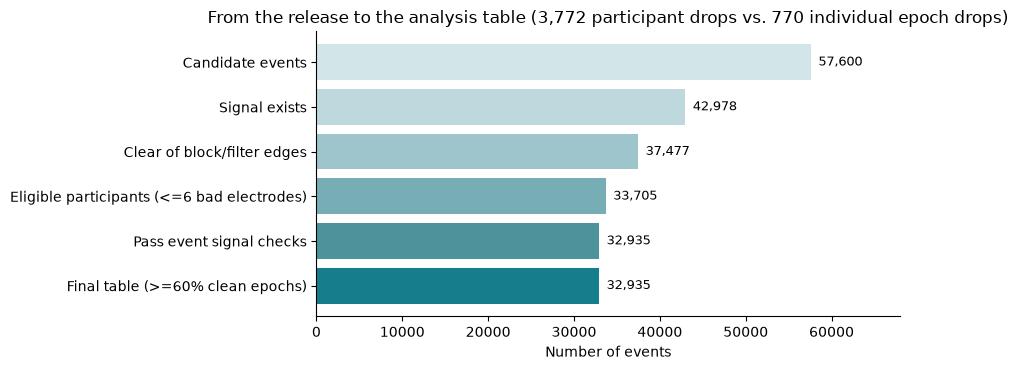

,excluded_events
reason,
filter_edge_guard,5501
participant:too_many_bad_channels,3772
signal:amplitude,770
source_severely_truncated,14400
source_unavailable,222


,subject,source_status,n_source_available,n_edge_eligible,n_signal_pass,n_included,participant_reason
0,sub-001,verified_prefix,1327,1143,1137,1137,NaN
1,sub-002,complete,1440,1288,1265,1265,NaN
2,sub-003,severely_truncated,0,0,0,0,source_severely_truncated
3,sub-004,severely_truncated,0,0,0,0,source_severely_truncated
4,sub-005,severely_truncated,0,0,0,0,source_severely_truncated
5,sub-006,complete,1440,1256,0,0,too_many_bad_channels
6,sub-007,severely_truncated,0,0,0,0,source_severely_truncated
7,sub-008,complete,1440,1252,1249,1249,NaN
8,sub-009,complete,1440,1255,1205,1205,NaN
9,sub-010,severely_truncated,0,0,0,0,source_severely_truncated


In [5]:
eligible_participants = int(
    (ledger.boundary_eligible & (ledger.reason != "participant:too_many_bad_channels")).sum()
)
flow = pd.Series({
    "Candidate events": len(ledger),
    "Signal exists": int(ledger.source_available.sum()),
    "Clear of block/filter edges": int(ledger.boundary_eligible.sum()),
    "Eligible participants (<=6 bad electrodes)": eligible_participants,
    "Pass event signal checks": int(ledger.signal_pass.sum()),
    "Final table (>=60% clean epochs)": int(ledger.included.sum()),
}, name="events")
display(flow.to_frame())

fig, ax = plt.subplots(figsize=(9.2, 3.8))
bars = flow.iloc[::-1]
ax.barh(bars.index, bars.values, color=["#167d8d", "#4e929b", "#77aeb6", "#9dc5cb", "#bed9dd", "#d2e5e8"])
for idx, count in enumerate(bars.values):
    ax.text(count + bars.max() * 0.015, idx, f"{count:,}", va="center", fontsize=9.5)
ax.set(
    title="From the release to the analysis table (3,772 participant drops vs. 770 individual epoch drops)",
    xlabel="Number of events",
    xlim=(0, bars.max() * 1.18),
)
plt.tight_layout(); plt.show()

display(ledger.loc[~ledger.included].groupby("reason").size().rename("excluded_events").to_frame())
display(audit[["subject", "source_status", "n_source_available", "n_edge_eligible", "n_signal_pass", "n_included", "participant_reason"]])

### Missingness, extreme feature values, and unequal classes

Missing EEG is not imputed. Source gaps and rejected epochs remain represented in the ledger, so every event missing from the final table has a recorded reason. Interpolation repairs an electrode from neighboring electrodes; it does not recover missing portions of a recording.

The final EEG features are all finite, with typical single-trial standard deviations of 4–7 µV, but a small tail reaches much larger magnitudes: 215 retained events (0.65%) exceed `±30 µV` on at least one feature and 48 (0.15%) exceed `±50 µV` (concentrated in four participants, including 41 events from `sub-036`). Joining those rows with the event ledger shows why they remain under fixed, label-blind rules:

- Epoch QC checks whether every channel's peak-to-peak excursion over `[−100, 400)` ms stays between `1` and `150 µV`. When slow drift above the 0.1 Hz high-pass cutoff or residual lateral/temporal noise moves steadily between the `[−100, 0)` ms baseline and a post-onset window while staying below `150 µV` peak-to-peak on every channel (for example, `sub-036_trial-0575` reaches `149.94 µV` peak-to-peak on `FT7`, and `sub-017_trial-0578` reaches `142.60 µV` on `FT8`), subtracting the baseline produces a large window mean (`+79.2 µV` and `−69.7 µV`) without triggering rejection.
- Passing the `150 µV` check does not make an epoch artifact-free. Residual muscle, ocular, drift or electrode activity may remain, including on the lateral temporal groups (`Ltemp`, `Rtemp`); large means alone do not identify their cause. We retain them under the stated rules rather than trim them to improve a score. Scaling and regularization do not remove artifacts; the next analysis should also report whether results depend strongly on extreme events or individual participants.

Standards are also much more frequent than deviants (84% vs. 16%). Exclusion rates are reported by condition below so class-dependent losses are visible; class counts are never used to choose the cleaning thresholds.

,missing
subject,0
trial,0
event_id,0
block,0
onset_s,0
condition,0
target,0
source_available,0
erp_Lfront_080_150_uv,0
erp_Lfront_150_250_uv,0


,candidates,source_available,boundary_eligible,included,retained_fraction_of_candidates,retained_fraction_of_edge_eligible,fraction_of_final_table
condition,,,,,,,
exemplar_dev,4360,3250,3011,2657,0.609,0.882,0.081
function_dev,4440,3318,2967,2615,0.589,0.881,0.079
standard,48800,36410,31499,27663,0.567,0.878,0.840


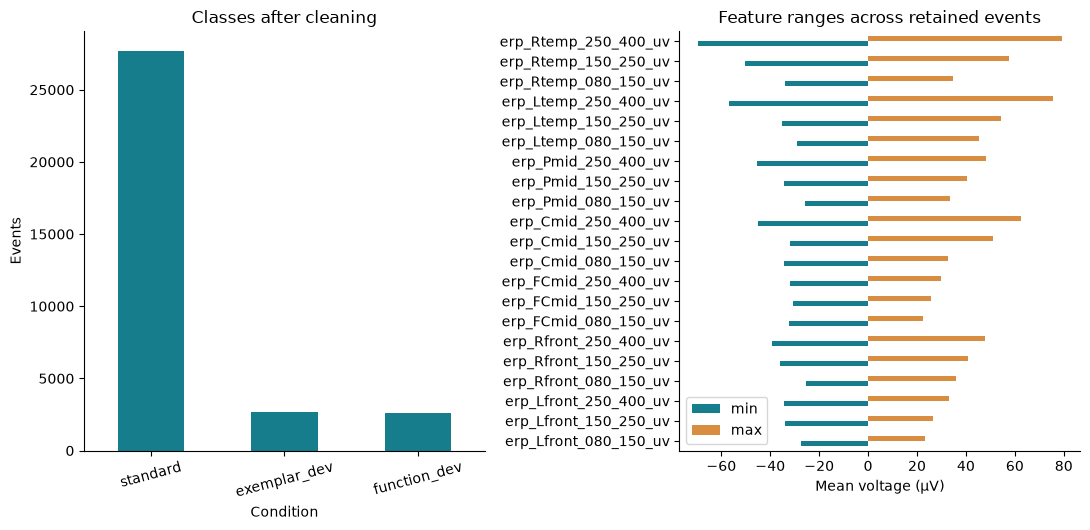

Retained events with |feature| > 30 µV: 215 (0.65%)
Retained events with |feature| > 50 µV: 48 (0.15%)
Participants with |feature| > 50 µV: {'sub-036': 41, 'sub-020': 3, 'sub-017': 2, 'sub-029': 2}


,event_id,condition,largest_feature,feature_value_uv,max_ptp_uv,worst_channel
27372,sub-036_trial-0575,standard,erp_Rtemp_250_400_uv,79.18,149.94,FT7
27462,sub-036_trial-0751,function_dev,erp_Ltemp_250_400_uv,75.41,123.28,T7
27494,sub-036_trial-0795,standard,erp_Rtemp_250_400_uv,75.12,133.20,P10
27816,sub-036_trial-1243,standard,erp_Ltemp_250_400_uv,73.02,127.29,FC5
27466,sub-036_trial-0758,standard,erp_Ltemp_250_400_uv,70.15,130.47,FC5
27813,sub-036_trial-1239,standard,erp_Ltemp_250_400_uv,69.98,131.26,T7


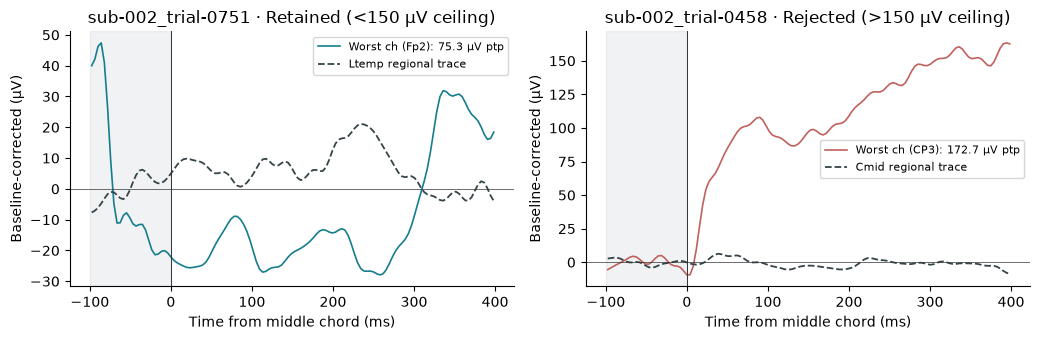

In [6]:
display(events.isna().sum().rename("missing").to_frame())
class_audit = ledger.groupby("condition").agg(
    candidates=("event_id", "size"), source_available=("source_available", "sum"),
    boundary_eligible=("boundary_eligible", "sum"), included=("included", "sum"))
class_audit["retained_fraction_of_candidates"] = class_audit.included / class_audit.candidates
class_audit["retained_fraction_of_edge_eligible"] = class_audit.included / class_audit.boundary_eligible
class_audit["fraction_of_final_table"] = class_audit.included / len(events)
display(class_audit.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 5.4))
events.condition.value_counts().plot.bar(ax=axes[0], color="#167d8d", rot=15)
axes[0].set(title="Classes after cleaning", ylabel="Events", xlabel="Condition")
events[PREDICTORS].agg(["min", "max"]).T.plot.barh(ax=axes[1], color=["#167d8d", "#d88d40"])
axes[1].set(title="Feature ranges across retained events", xlabel="Mean voltage (µV)", ylabel="")
plt.tight_layout(); plt.show()

ledger_ptp = ledger[["event_id", "worst_channel"]].assign(
    max_ptp_uv=pd.to_numeric(ledger["max_ptp_uv"], errors="coerce")
)
extreme_check = events.merge(ledger_ptp, on="event_id")
extreme_check["max_abs_feature_uv"] = extreme_check[PREDICTORS].abs().max(axis=1)
extreme_check["largest_feature"] = extreme_check[PREDICTORS].abs().idxmax(axis=1)
extreme_check["feature_value_uv"] = [
    row[col] for _, row in extreme_check.iterrows() for col in [row["largest_feature"]]
]
n_gt30 = int((extreme_check["max_abs_feature_uv"] > 30).sum())
n_gt50 = int((extreme_check["max_abs_feature_uv"] > 50).sum())
print(f"Retained events with |feature| > 30 µV: {n_gt30:,} ({n_gt30 / len(events):.2%})")
print(f"Retained events with |feature| > 50 µV: {n_gt50:,} ({n_gt50 / len(events):.2%})")
print("Participants with |feature| > 50 µV:", extreme_check.loc[extreme_check["max_abs_feature_uv"] > 50, "subject"].value_counts().to_dict())
display(
    extreme_check.sort_values("max_abs_feature_uv", ascending=False)[
        ["event_id", "condition", "largest_feature", "feature_value_uv", "max_ptp_uv", "worst_channel"]
    ].head(6).round(2)
)

with np.load(RESULTS / "example.npz") as saved:
    ex_traces = {name: saved[name] for name in saved.files}
ex_ids = [str(x) for x in ex_traces["event_ids"]]
ex_ledger = ledger_ptp.set_index("event_id").loc[ex_ids]
retained_indices = np.flatnonzero(ex_traces["included"])
high_ret_idx = int(retained_indices[np.argmax(ex_ledger.iloc[retained_indices]["max_ptp_uv"].to_numpy())])
rejected_indices = np.flatnonzero(~ex_traces["included"])
near_rej_idx = int(rejected_indices[np.argmin(ex_ledger.iloc[rejected_indices]["max_ptp_uv"].to_numpy())])

ch_names = list(ex_traces["channel_names"])
t_ms = ex_traces["times_s"] * 1000
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
for ax, idx, status, reg_name, color in [
    (axes[0], high_ret_idx, "Retained (<150 µV ceiling)", "Ltemp", "#167d8d"),
    (axes[1], near_rej_idx, "Rejected (>150 µV ceiling)", "Cmid", "#c0615e"),
]:
    eid = ex_ids[idx]
    worst_ch = str(ex_ledger.loc[eid, "worst_channel"])
    ptp_val = float(ex_ledger.loc[eid, "max_ptp_uv"])
    ch_i = ch_names.index(worst_ch)
    reg_idx = [ch_names.index(c) for c in ROIS[reg_name]]
    ax.plot(t_ms, ex_traces["baseline_corrected_uv"][idx, ch_i], color=color, lw=1.2, label=f"Worst ch ({worst_ch}): {ptp_val:.1f} µV ptp")
    ax.plot(t_ms, ex_traces["baseline_corrected_uv"][idx, reg_idx].mean(axis=0), color="#354449", lw=1.3, ls="--", label=f"{reg_name} regional trace")
    ax.axvspan(-100, 0, color="#99a7b2", alpha=0.14)
    ax.axvline(0, color="#333", lw=0.7); ax.axhline(0, color="#333", lw=0.5)
    ax.set(title=f"{eid} · {status}", xlabel="Time from middle chord (ms)", ylabel="Baseline-corrected (µV)")
    ax.legend(fontsize=8, loc="best")
plt.tight_layout(); plt.show()

### Participant-weighted condition window averages

To see the scale of average condition differences relative to single-trial variability, the plot below computes each participant's mean within each condition and then averages equally across the 27 retained participants for `FCmid` and `Pmid`.

- Each point is one of the three regional window averages (`80–150`, `150–250`, and `250–400` ms), so the points summarize separate windows rather than tracing a continuous ERP waveform.
- Across participants, condition window averages differ by roughly `0.4–1.3 µV`, whereas single-trial standard deviations within those same columns are `4.4–6.1 µV`. That contrast explains why single trials overlap heavily. The evaluation must also respect repeated observations within participants.
- These differences are descriptive. On their own they do not show that the timing is exact, that cleaning removed every artifact, or that the brain is responding to surprise alone.

condition,standard,exemplar_dev,function_dev,single_trial_sd
erp_FCmid_080_150_uv,-0.552,-0.510,-0.632,4.426
erp_FCmid_150_250_uv,0.207,-0.220,-0.501,4.748
erp_FCmid_250_400_uv,-0.076,-0.374,-0.471,5.171
erp_Pmid_080_150_uv,0.610,0.480,0.748,5.123
erp_Pmid_150_250_uv,0.591,0.934,1.261,5.477
erp_Pmid_250_400_uv,0.545,1.487,1.857,6.123


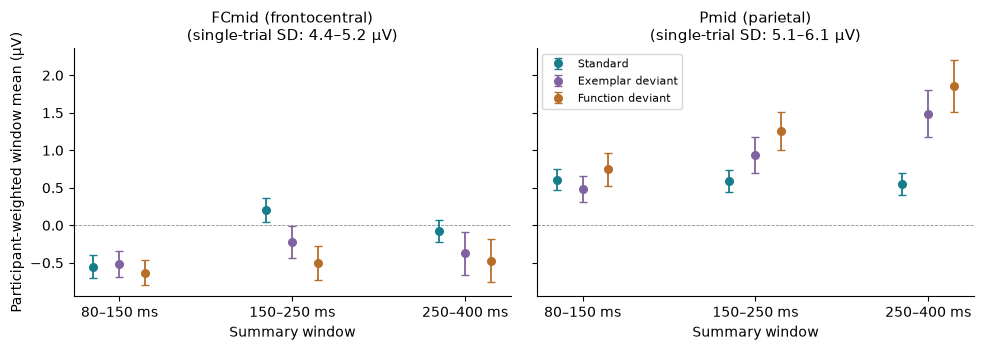

In [7]:
subject_condition_means = events.groupby(["subject", "condition"])[PREDICTORS].mean()
condition_window_means = subject_condition_means.groupby("condition").mean()
condition_window_sems = subject_condition_means.groupby("condition").sem()

summary_cols = [f"erp_{roi}_{w}_uv" for roi in ("FCmid", "Pmid") for w in WINDOWS]
summary_table = condition_window_means.loc[["standard", "exemplar_dev", "function_dev"], summary_cols].T
summary_table["single_trial_sd"] = events[summary_cols].std()
display(summary_table.round(3))

window_keys = list(WINDOWS.keys())
window_labels = [f"{int(start * 1000)}–{int(stop * 1000)} ms" for start, stop in WINDOWS.values()]
x_pos = np.arange(len(window_keys))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, roi, label in zip(axes, ["FCmid", "Pmid"], ["FCmid (frontocentral)", "Pmid (parietal)"]):
    cols = [f"erp_{roi}_{w}_uv" for w in window_keys]
    sds = events[cols].std()
    ax.axhline(0, color="#839095", lw=0.6, ls="--")
    for cond, name, color, offset in [
        ("standard", "Standard", "#167d8d", -0.15),
        ("exemplar_dev", "Exemplar deviant", "#80629e", 0.0),
        ("function_dev", "Function deviant", "#b66e29", 0.15),
    ]:
        means = [condition_window_means.loc[cond, c] for c in cols]
        sems = [condition_window_sems.loc[cond, c] for c in cols]
        ax.errorbar(x_pos + offset, means, yerr=sems, fmt="o", color=color, capsize=3, lw=1.3, ms=5.5, label=name)
    ax.set_xticks(x_pos, window_labels)
    ax.set_title(f"{label}\n(single-trial SD: {sds.min():.1f}–{sds.max():.1f} µV)", fontsize=10.5)
    ax.set_xlabel("Summary window")
axes[0].set_ylabel("Participant-weighted window mean (µV)")
axes[1].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

### Information leakage

A column leaks if it carries information about the label that a genuine prediction could not use.

- `condition` and `target` are the label itself.
- `trial`, `block`, `onset_s`, and `event_id` give the label away. Every participant heard the same sequence, so the trial number alone identifies the deviants (checked below). Holding out whole participants does not fix this, so these columns are never predictors.
- Within every block, the first nine trials are always standards.
- The cleaning rules never look at the label. The share of epochs rejected for amplitude is about the same in each condition (below).
- Scaling and any other fitted step will be learned on the training folds only.
- Participants pressed a button for deviants, and some presses come before 400 ms. The latest window (250–400 ms) may therefore partly reflect movement preparation, not hearing alone.

In [8]:
in_order = ledger.sort_values(["subject", "trial"])
position = in_order.groupby(["subject", "block"]).cumcount() + 1
print("Same condition at each trial number for every participant:", in_order.groupby("trial").condition.nunique().max() == 1)
print("Trials 1-9 of every block are standards:", (in_order.condition[position <= 9] == "standard").all())

checked = ledger[ledger.boundary_eligible & (ledger.reason != "participant:too_many_bad_channels")]
rejected = (checked.reason == "signal:amplitude").groupby(checked.condition).mean()
display(rejected.rename("share rejected for amplitude").to_frame().round(3))

Same condition at each trial number for every participant: True
Trials 1-9 of every block are standards: True


,share rejected for amplitude
condition,
exemplar_dev,0.019
function_dev,0.021
standard,0.023


### One event becomes one table row

The example below is a real retained event, shown after filtering and artifact correction. The baseline interval falls during the first chord, so the listener is already hearing music. Shaded areas mark the three averaging windows.

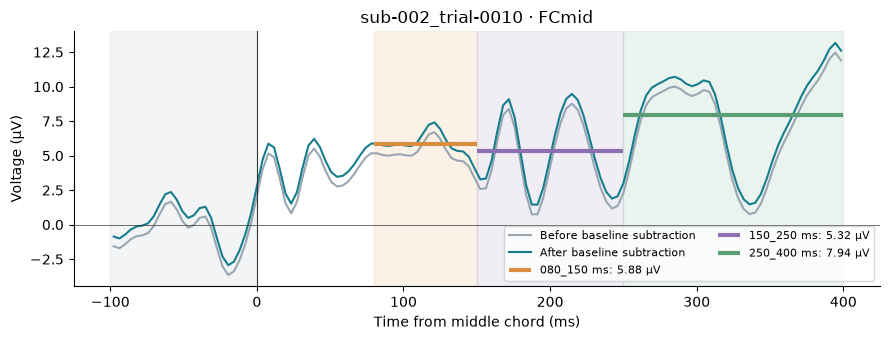

,table value (µV)
erp_FCmid_080_150_uv,5.877933
erp_FCmid_150_250_uv,5.31636
erp_FCmid_250_400_uv,7.940117


In [9]:
with np.load(RESULTS / "example.npz") as saved:
    example = {name: saved[name] for name in saved.files}
index = int(np.flatnonzero(example["included"])[0])
region = "FCmid"
channels = list(example["channel_names"])
indices = [channels.index(name) for name in ROIS[region]]
time_ms = example["times_s"] * 1000
before_baseline = example["clean_uv"][index, indices].mean(axis=0)
corrected = example["baseline_corrected_uv"][index, indices].mean(axis=0)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(time_ms, before_baseline, color="#99a7b2", label="Before baseline subtraction")
ax.plot(time_ms, corrected, color="#167d8d", label="After baseline subtraction")
ax.axvspan(-100, 0, color="#99a7b2", alpha=.12)
for (window, (start, stop)), color in zip(WINDOWS.items(), ["#d88d40", "#8d70b1", "#5b9e76"]):
    mask = (example["times_s"] >= start) & (example["times_s"] < stop)
    mean = corrected[mask].mean()
    ax.axvspan(start * 1000, stop * 1000, color=color, alpha=.12)
    ax.hlines(mean, start * 1000, stop * 1000, color=color, lw=3, label=f"{window} ms: {mean:.2f} µV")
ax.axvline(0, color="#333", lw=.8); ax.axhline(0, color="#333", lw=.5)
ax.set(title=f"{example['event_ids'][index]} · {region}", xlabel="Time from middle chord (ms)", ylabel="Voltage (µV)")
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()
row = events.set_index("event_id").loc[str(example["event_ids"][index])]
display(row[[name for name in PREDICTORS if name.startswith(f"erp_{region}_")]].to_frame("table value (µV)"))

## 4. Refined question and next analysis

**Question:** Can 21 early EEG voltage features tell standard from deviant middle chords in participants the model was not trained on?

**How we will know:** the answer is *yes* if a model evaluated with participant-grouped cross-validation reaches a held-out ROC AUC above 0.5, with a bootstrap confidence interval over held-out participants that excludes 0.5, and beats the class-prior baseline on balanced accuracy. (Always guessing "standard" is 84% accurate but has a balanced accuracy of 0.5 and an AUC of 0.5.) Otherwise we did not demonstrate above-chance prediction under this evaluation.

The question is about prediction. A yes would not by itself explain why the responses differ, because standards and deviants also differ in sound, attention, and button presses.

The next milestone can begin with regularized logistic regression and a simple decision tree, using participant-grouped cross-validation. Report ROC AUC and balanced accuracy alongside the class counts, not accuracy alone. Because standards make up 84% of the retained events, address class imbalance inside each training fold—for example with balanced class weights or decision thresholds selected strictly on training-fold predictions—and fit feature scaling only on the training folds.

The code below sets up the split without fitting a model. Each participant stays wholly on one side. Each participant's recording is cleaned on its own and without labels, so cleaning does not pool estimates between training and test participants. It does use the held-out participant's complete unlabeled recording, an offline assumption that would not describe immediate prediction from an arriving event.

In [10]:
from sklearn.model_selection import GroupKFold

X = events[PREDICTORS]
y = events.target
groups = events.subject
splitter = GroupKFold(n_splits=5)
splits = []
for fold, (train, test) in enumerate(splitter.split(X, y, groups), start=1):
    train_people = set(groups.iloc[train]); test_people = set(groups.iloc[test])
    assert train_people.isdisjoint(test_people)
    splits.append({"fold": fold, "training_participants": len(train_people),
                   "test_participants": len(test_people), "training_events": len(train), "test_events": len(test)})
display(pd.DataFrame(splits))

,fold,training_participants,test_participants,training_events,test_events
0,1,21,6,25747,7188
1,2,21,6,25700,7235
2,3,22,5,26762,6173
3,4,22,5,26760,6175
4,5,22,5,26771,6164


## 5. References and citations

### Dataset and experimental studies
- **Dataset:** Goldman, A., Jackson, T., & Sajda, P. (2026). *EEG: Improvisation and Musical Structures* (Version 1.0.0) [Dataset]. NEMAR (`on003570`), https://doi.org/10.82901/nemar.on003570 (mirroring OpenNeuro `ds003570`, https://doi.org/10.18112/openneuro.ds003570.v1.0.0).
- **Original EEG study:** Faller, J., Goldman, A., Lin, Y., McIntosh, J. R., & Sajda, P. (2021). Spatiospectral brain networks reflective of improvisational experience. *NeuroImage*, 242, 118458. https://doi.org/10.1016/j.neuroimage.2021.118458
- **Behavioral background study:** Goldman, A., Jackson, T., & Sajda, P. (2020). Improvisation experience predicts how musicians categorize musical structures. *Psychology of Music*, 48(1), 18–34. https://doi.org/10.1177/0305735618779444

### EEG preprocessing and scientific software
- **MNE-Python:** Gramfort, A., Luessi, M., Larson, E., Engemann, D. A., Strohmeier, D., Brodbeck, C., Goj, R., Jas, M., Brooks, T., Parkkonen, L., & Hämäläinen, M. S. (2013). MEG and EEG data analysis with MNE-Python. *Frontiers in Neuroscience*, 7, 267. https://doi.org/10.3389/fnins.2013.00267
- **PREP pipeline & PyPREP:** Bigdely-Shamlo, N., Mullen, T., Kothe, C., Su, K.-M., & Robbins, K. A. (2015). The PREP pipeline: standardized preprocessing for large-scale EEG analysis. *Frontiers in Neuroinformatics*, 9, 16. https://doi.org/10.3389/fninf.2015.00016 (`PyPREP`: https://pyprep.readthedocs.io/)
- **Picard ICA:** Ablin, P., Cardoso, J.-F., & Gramfort, A. (2018). Faster independent component analysis by preconditioning with Hessian approximations. *IEEE Transactions on Signal Processing*, 66(15), 4040–4049. https://doi.org/10.1109/TSP.2018.2844203
- **ICLabel & MNE-ICALabel:** Pion-Tonachini, L., Kreutz-Delgado, K., & Makeig, S. (2019). ICLabel: An automated electroencephalographic independent component classifier, dataset, and website. *NeuroImage*, 198, 181–197. https://doi.org/10.1016/j.neuroimage.2019.05.026; Li, A., Feitelberg, J., Saini, A. P., Höchenberger, R., & Scheltienne, M. (2022). MNE-ICALabel: Automatically annotating ICA components with ICLabel in Python. *Journal of Open Source Software*, 7(76), 4484. https://doi.org/10.21105/joss.04484
- **Validation & tabular tools:** Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830 (alongside NumPy, SciPy, pandas, PyArrow, and Matplotlib).

### Generative AI disclosure
- **OpenAI Codex (`GPT-6 Astra`, `GPT-6.1 Sol`, `GPT-6 Luna`; November 2026):** Used for an earlier preprocessing prototype and documentation handoff (`GPT-6 Astra`, `GPT-6.1 Sol`, `GPT-6 Luna`), implementation of `eeg_pipeline/`, the test suite, `ms2_data.ipynb`, `docs/methods.md`, and `docs/explainer.html`, and technical review (`GPT-6 Astra`).
- **Anthropic Claude Code (`Claude Opus 5.5`; November 2026):** Used for an earlier reference prototype, cross-review of preprocessing and cohort choices, and readability and wording edits to `ms2_data.ipynb`, `README.md`, `docs/methods.md`, and `docs/explainer.html`.
- **Google Antigravity (`Gemini 4 Argon`; November 2026):** Used for adversarial review and updates to cross-platform line-ending handling, exclusion and condition-window charts, extreme-value diagnostics, and citations.